# 05 - Business Insights: Restaurant Scorecard and Recommendations

Combine everything built so far (cleaning → complaints → sentiment → TF-IDF) with the restaurant metadata (cost, cuisine) to answer **business questions**:

1. Which restaurants need attention first, and *why*?
2. Which complaint types cost the most stars?
3. Does delivery speed affect ratings?
4. Is price related to satisfaction?
5. Is quality improving or declining over time?

In [1]:
import sys, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")
import re
import pandas as pd
import numpy as np
from IPython.display import display, Image
pd.set_option("display.max_colwidth", 140)
pd.set_option("display.width", 180)
from run_pipeline import build_dataset
df, meta, log = build_dataset()
print("Rows:", len(df), "| Columns:", df.shape[1])
print(log)

Rows: 9944 | Columns: 49
{'raw_rows': 10000, 'after_drop_empty_rows': 9962, 'non_numeric_ratings': 1, 'after_drop_empty_text': 9944, 'repeat_reviewer_text_kept': 6}


## 1. Restaurant attention score
`attention_score (0-100) = 50% rating gap (5 − avg stars) + 30% complaint rate + 20% share of negative-text reviews`.
The weights are a judgement call, documented here so they can be changed; the individual components are kept in the table.

In [2]:
sc = pd.read_csv("../outputs/tables/restaurant_scorecard.csv")
cols = ["Restaurant","reviews","avg_rating","pct_1_2_star","complaint_rate","top_complaint","attention_score","cost_for_two","primary_cuisine"]
sc[cols].head(12)

,Restaurant,reviews,avg_rating,pct_1_2_star,complaint_rate,top_complaint,attention_score,cost_for_two,primary_cuisine
0,Hotel Zara Hi-Fi,100,2.40,64.00,60.00,Food Quality,60.5,400,Chinese
1,Asian Meal Box,100,2.58,52.00,46.00,Food Quality,51.8,200,Asian
2,Pakwaan Grand,100,2.71,46.00,46.00,Food Quality,50.0,400,North Indian
3,Mathura Vilas,100,2.82,43.00,53.00,Staff & Service,49.6,500,South Indian
4,The Chocolate Room,100,2.83,45.00,42.00,Food Quality,46.9,600,Cafe
5,Behrouz Biryani,100,2.82,47.00,45.00,Food Quality,46.7,600,Mughlai
6,Shree Santosh Dhaba Family Restaurant,97,2.78,48.45,37.11,Food Quality,46.5,500,North Indian
7,KFC,99,2.83,44.44,37.37,Food Quality,45.0,500,Burger
8,Delhi-39,100,2.98,43.00,41.00,Food Quality,44.4,600,North Indian
9,Club Rogue,100,2.88,41.00,36.00,Staff & Service,43.9,900,North Indian


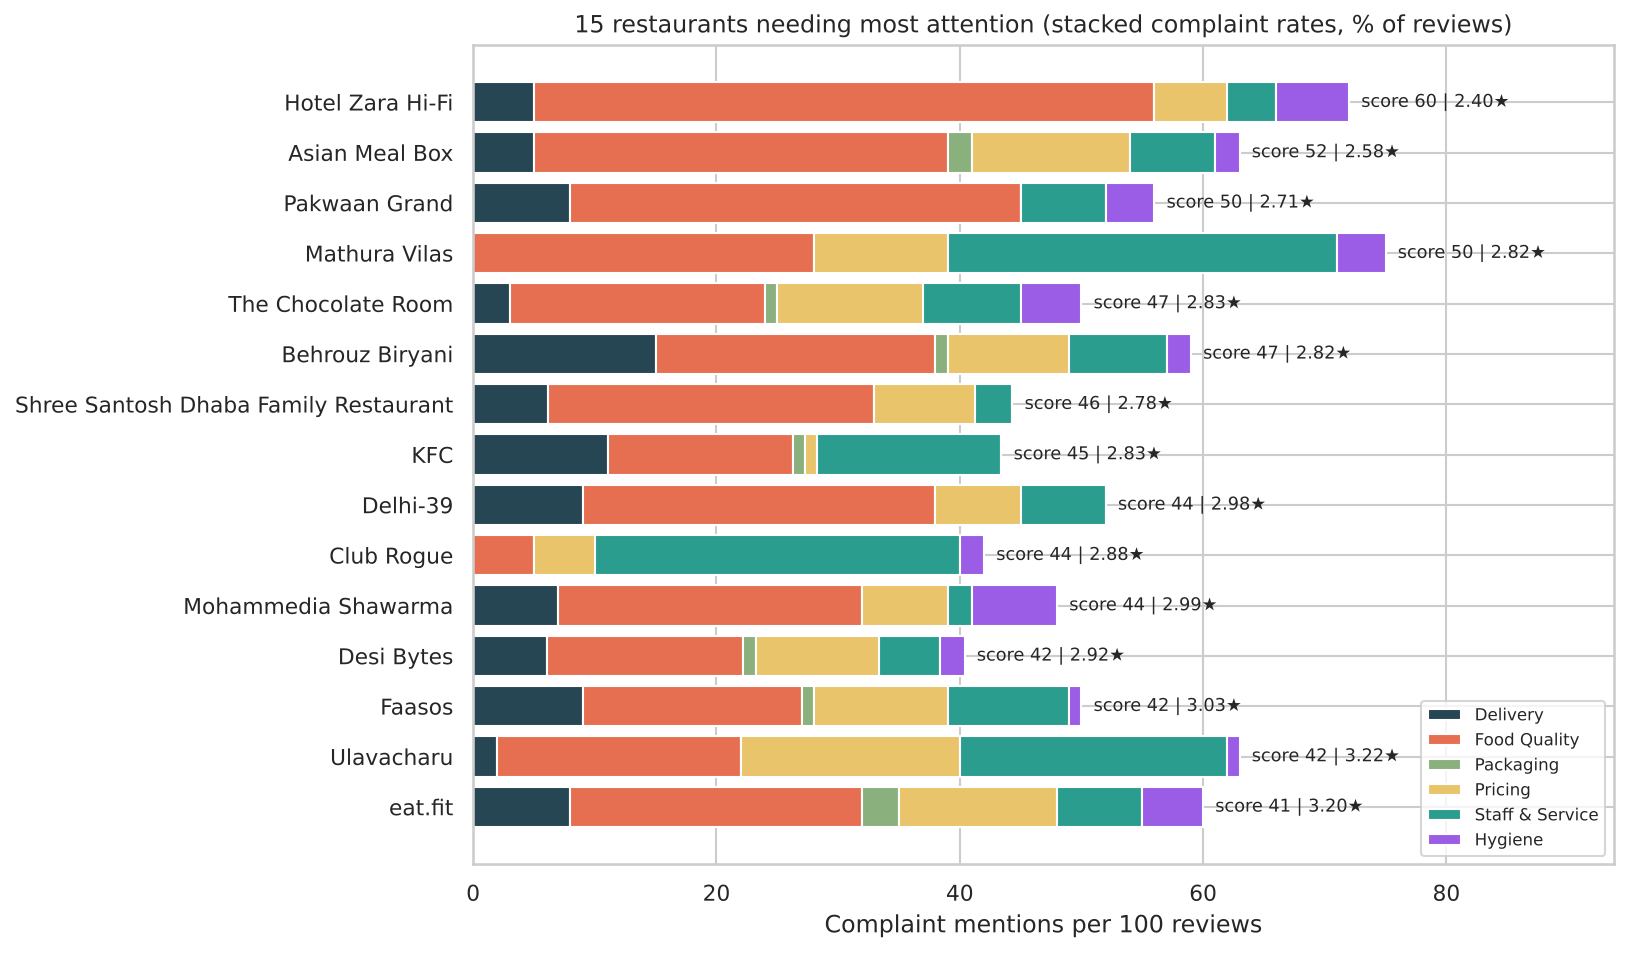

In [3]:
Image("../outputs/figures/08_restaurant_priority.png")

**Reading it:** each bar is a restaurant's complaint mentions per 100 reviews, split by category - the colour mix is the *action plan*. For example a bar dominated by teal (Staff & Service) is a training problem, orange (Food Quality) a kitchen problem, dark (Delivery) a logistics problem.

Drill-down: the actual voice of the customer for the #1 restaurant.

In [4]:
top = sc.iloc[0].Restaurant
print("Top attention restaurant:", top, "| avg rating", sc.iloc[0].avg_rating, "| signature terms:", sc.iloc[0].signature_terms)
pd.set_option("display.max_colwidth", 250)
df[(df.Restaurant==top) & (df.has_complaint)][["Rating","complaint_categories","Review_clean"]].head(6)

Top attention restaurant: Hotel Zara Hi-Fi | avg rating 2.4 | signature terms: zara, hotel zara, zara hi, hi fi, afghani chicken


,Rating,complaint_categories,Review_clean
1699,1,Food Quality,terrible chicken masala curry had only 1 piece which was about one inch square on the bone extremely hot cant taste any major spiced except loaded red chilly gave me gas for a good 30 mins
1702,1,Hygiene,i received hens hair in chicken haleem also i ordered chicken 65 biryani but received veg biryani what kind of customer service is that
1703,1,Food Quality,yukkkkkksssssssss yukkkssssssssssss i can not write anything more the afghani chicken was bad only the omlet in it was good chicken pieces were horrible
1704,1,Food Quality,chicken 65 not good because small and cooler red more and more udjjsekjawigsjeisijueusoawjhssslbsksoegjsfak date s have hdaivdbskbduauhsjsjjskakskskskhdvdhsjs
1705,1,Hygiene,very bad and untasty food i doubt if it was even fresh the chicken looked so unhygienic and old i would not recommend this place to anyone
1706,2,Food Quality,i ordered 1 plate noodles 1 plate manchurian from which noodles taste was very bad so i recommend that not order noodles from this restaurant


In [5]:
print("Best performers:")
sc.sort_values("avg_rating", ascending=False)[["Restaurant","avg_rating","complaint_rate","top_complaint","cost_for_two","primary_cuisine"]].head(8)

Best performers:


,Restaurant,avg_rating,complaint_rate,top_complaint,cost_for_two,primary_cuisine
99,AB's - Absolute Barbecues,4.88,2.0,Food Quality,1500,European
98,B-Dubs,4.81,5.0,Pricing,1600,American
97,"3B's - Buddies, Bar & Barbecue",4.76,5.0,Staff & Service,1100,North Indian
96,Paradise,4.70,5.0,Food Quality,800,Biryani
95,Flechazo,4.66,8.0,Food Quality,1300,Asian
94,The Indi Grill,4.60,13.0,Food Quality,1500,BBQ
93,Zega - Sheraton Hyderabad Hotel,4.45,17.0,Food Quality,1750,Asian
92,Over The Moon Brew Company,4.34,15.0,Staff & Service,1200,Asian


## 2. Which complaint types matter most? (volume × damage)

In [6]:
from src import analysis as an
summary = an.complaint_summary(df); summary

,category,reviews,share_of_reviews_%,avg_rating_when_present,avg_rating_when_absent,rating_drop,pct_1_2_star_%,avg_vader,priority_rank
0,Food Quality,1648,16.6,2.06,3.91,-1.84,64.8,-0.028,1
1,Staff & Service,967,9.7,2.18,3.75,-1.58,62.8,0.016,2
2,Pricing,674,6.8,2.82,3.66,-0.84,41.2,0.248,3
3,Delivery,243,2.4,1.72,3.65,-1.93,78.2,-0.129,4
4,Hygiene,200,2.0,1.66,3.64,-1.98,81.0,-0.223,5
5,Packaging,40,0.4,2.25,3.60,-1.35,60.0,-0.102,6


* **Food Quality** is the single biggest lever: most mentions *and* ~1.8 stars lost per mention.
* **Staff & Service** is second by volume.
* **Hygiene, Delivery** are rare but cause the largest drop per mention (~2 stars), and 78-81% of those reviews are 1-2★.
* **Pricing** is frequent but milder (~0.8 stars) - customers grumble about price yet still rate decently.

## 3. Delivery speed vs rating
Only reviews that mention an actual time (n≈74) are included, which biases toward people who were annoyed enough to mention it - read as direction, not as a population estimate.

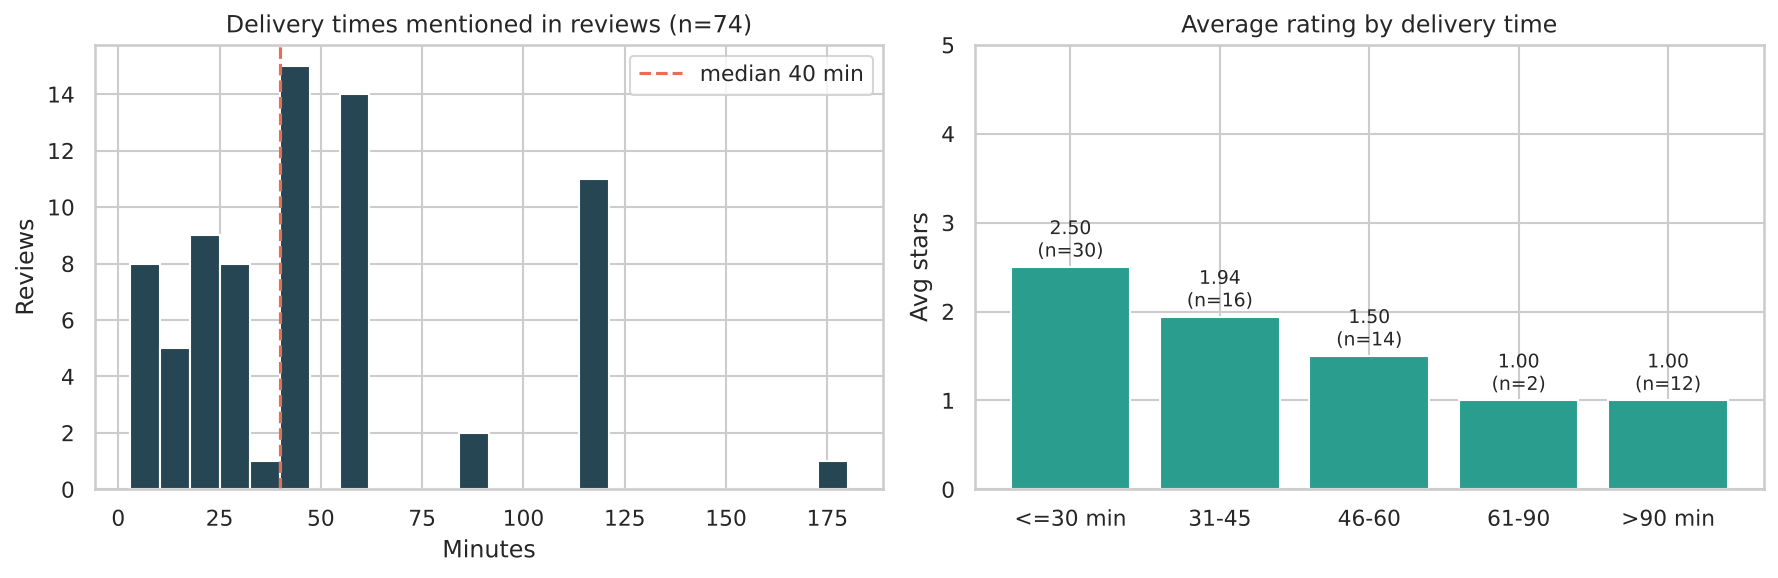

In [7]:
Image("../outputs/figures/07_delivery_time.png")

In [8]:
pd.read_csv("../outputs/tables/delivery_time_vs_rating.csv")

,delivery_bucket,reviews,avg_rating,pct_negative_text
0,<=30 min,30,2.50,40.00
1,31-45,16,1.94,43.75
2,46-60,14,1.50,57.14
3,61-90,2,1.00,0.00
4,>90 min,12,1.00,66.67


Ratings fall steadily as stated delivery time grows - from about 2.5★ (≤30 min) to about 1.0★ (>90 min). Even short stated times have low ratings because people mostly *mention* a time when something went wrong.

### Delivery / online-order reviews vs dine-in reviews

In [9]:
pd.read_csv("../outputs/tables/delivery_vs_dinein.csv")

,is_delivery_context,reviews,avg_rating,complaint_rate,negative_text_rate,rate_delivery,rate_food_quality,rate_packaging,rate_pricing,rate_staff_service,rate_hygiene
0,Dine-in / other,8688,3.67,28.0,17.3,0.8,16.1,0.3,6.9,9.4,2.0
1,Delivery / online order,1256,3.14,40.5,27.1,14.0,19.7,1.2,6.1,11.7,2.1


Reviews written in a delivery context (12.6% of all reviews) average **3.14★ vs 3.67★** for dine-in, have a higher complaint rate (**40.5% vs 28.0%**) and 27% negative text vs 17%. Beyond the obvious delivery complaints (14.0 vs 0.8 per 100 reviews), delivery reviews also have more **packaging** (1.2 vs 0.3) and **food-quality** (19.7 vs 16.1) complaints: food arriving cold, spilled or wrong. The delivery-context flag is a keyword proxy (deliver, zomato, swiggy, parcel...), not an official order-type field.

## 4. Price and satisfaction

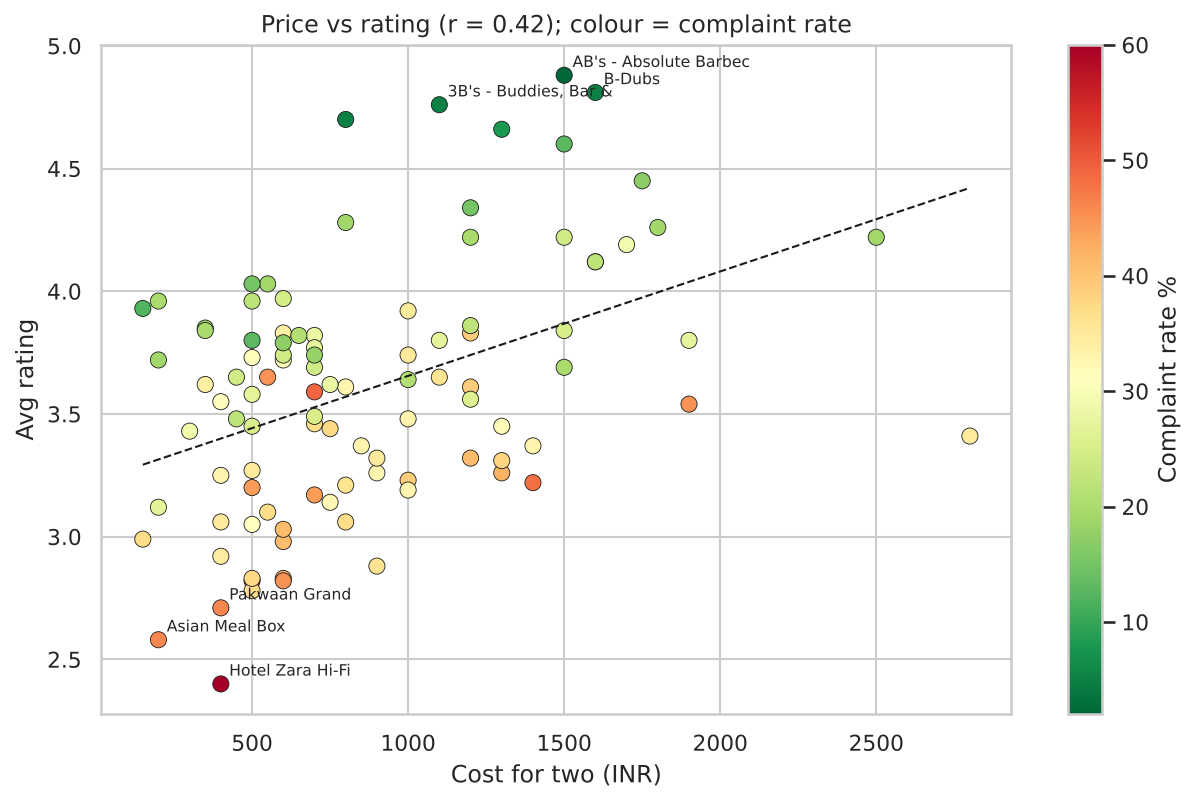

In [10]:
Image("../outputs/figures/10_cost_vs_rating.png", width=640)

In [11]:
print("Correlation cost-for-two vs avg rating:", round(sc.cost_for_two.corr(sc.avg_rating),2))
display(pd.read_csv("../outputs/tables/cost_band_summary.csv"))
display(pd.read_csv("../outputs/tables/cuisine_summary.csv"))

Correlation cost-for-two vs avg rating: 0.42


,cost_band,restaurants,avg_rating,complaint_rate,avg_cost
0,Premium (>1000),31,3.95,26.07,1495.16
1,Upper-mid (701-1000),18,3.51,31.13,877.78
2,Mid (401-700),35,3.48,31.19,577.14
3,Budget (<=400),16,3.31,31.32,303.12


,primary_cuisine,restaurants,avg_rating,complaint_rate,avg_cost
0,American,4,4.00,19.42,925.00
1,Asian,5,3.94,24.40,1110.00
2,Bakery,5,3.71,28.20,610.00
3,Biryani,4,3.66,24.00,700.00
4,Continental,4,3.66,32.82,1537.50
5,Cafe,5,3.54,34.80,640.00
6,North Indian,32,3.54,29.79,929.69
7,Chinese,7,3.35,36.81,850.00


Higher-priced restaurants are rated more favourably (r ≈ 0.4; premium avg 3.95★ vs budget 3.31★). Budget places draw more **food-quality** (19.6 vs 13.5 mentions per 100 reviews) and **hygiene** complaints (3.2 vs 1.2) than premium ones, while premium and upper-mid places draw far more **service** complaints (12.6-13.1 vs 4.8 for budget) - diners paying more expect more attentive service. Correlation, not causation: price also proxies for chain quality, location and clientele.

## 5. Trend over time

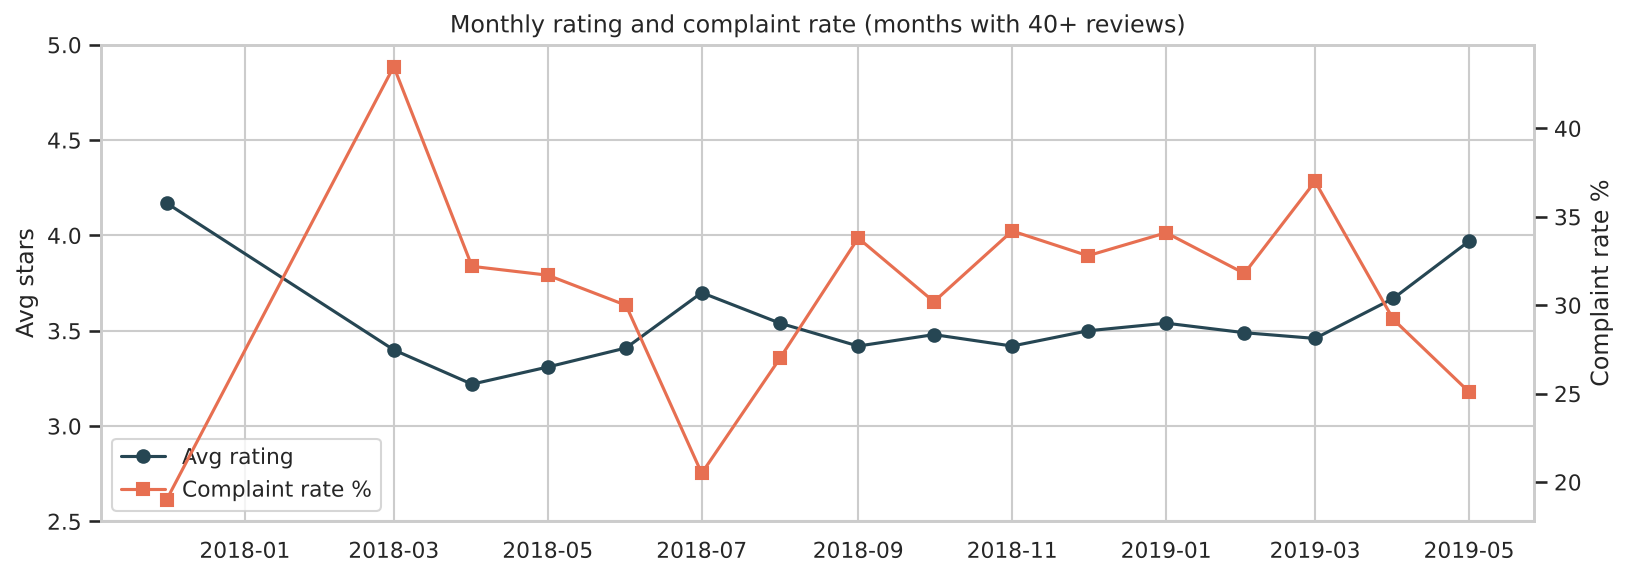

In [12]:
Image("../outputs/figures/09_monthly_trend.png")

In [13]:
pd.read_csv("../outputs/tables/monthly_trend.csv").tail(10)

,review_month,reviews,avg_rating,complaint_rate,negative_text_rate
6,2018-08,644,3.54,27.0,17.9
7,2018-09,621,3.42,33.8,23.2
8,2018-10,603,3.48,30.2,19.6
9,2018-11,523,3.42,34.2,20.1
10,2018-12,543,3.50,32.8,18.6
11,2019-01,621,3.54,34.1,18.5
12,2019-02,698,3.49,31.8,20.9
13,2019-03,1013,3.46,37.0,20.6
14,2019-04,1124,3.67,29.2,17.8
15,2019-05,1347,3.97,25.1,15.1


From Aug 2018 to Mar 2019 the average rating is flat at roughly 3.4-3.5★ with a 27-37% complaint rate. April-May 2019 look better (3.67★ and 3.97★, complaint rate down to 25%). **Treat this cautiously**: the file holds roughly the latest 100 reviews per restaurant, so busy restaurants fill their 100 slots in a few weeks while quiet ones span years. Month-level comparisons mix restaurant volume with quality, and the July 2018 spike (1,297 reviews) is a sampling artefact. A proper trend needs a per-restaurant time series.

## 6. Recommendations (what a restaurant operator or Zomato account manager would do)

1. **Triage list:** review the top-15 attention restaurants monthly, using the colour mix to route the issue to kitchen, floor staff or logistics.
2. **Food quality first:** ~1 in 6 reviews contains a food-quality complaint, and each costs ~1.8★. Stale / cold / undercooked / tasteless are recurring phrases; temperature-holding and freshness checks are the likely fix.
3. **Service training and wait-time management:** second-largest category; "waited", "had to ask", "rude" dominate. Quick wins: table-ready alerts, order-status SLA.
4. **Delivery:** set an alert when delivery exceeds 60 minutes - reviews citing >60 min average ~1★.
5. **Hygiene:** zero-tolerance escalation - rare (2%) but 81% of mentions are 1-2★ and they go viral.
6. **Don't rely on sentiment alone:** polite pricing/service complaints are under-detected by VADER; use the category flags.

## 7. Limitations and next steps
* Rule-based complaints: ~80-90% precision on spot checks, recall ~70% on 1-2★ reviews. Next: label 500 reviews, measure precision/recall, then train a classifier (TF-IDF + logistic regression or a transformer).
* Sarcasm and mixed reviews remain hard for VADER; aspect-based sentiment (sentiment *per topic*) is the natural upgrade.
* Dataset: ~100 reviews per restaurant (an equal sample), so volume comparisons between restaurants are not possible, only rate comparisons.
* Reviews span 2016-2019; the data is historical.